# **C18 - VaR y CVaR**
## **Simulación de Procesos Financieros**

---

**Autor:** Francisco Uriel Ledezma Chávez  
**Carrera:** Ingeniería Financiera  
**Institución:** ITESO — Universidad Jesuita de Guadalajara  
**Semestre:** 5° — Simulación de Procesos Financieros  
**Fecha de realización:** 11 de noviembre de 2026

---

**Ejercicio:** medir el riesgo de invertir 100,000 dólares durante un año en AAPL, MSFT y NVDA con tres estrategias, todo en AAPL, en partes casi iguales y con 60% en NVDA, para lo cual se estiman la media y la volatilidad logarítmicas de cada acción sobre el último año de precios, se simulan 10,000 escenarios correlacionados con la descomposición de Cholesky, se calcula en cada uno la ganancia de cada estrategia y se resume su cola izquierda con el valor en riesgo (VaR) y el valor en riesgo condicional (CVaR) al 5%.

C16-C17 midió el riesgo de un portafolio con la desviación estándar de su valor final y con la probabilidad de terminar por debajo del capital, mientras que aquí la medida se expresa en dinero, ya que el VaR indica cuánto puede perderse en un año con 95% de confianza y el CVaR cuánto se pierde en promedio en los escenarios que rebasan ese umbral, de modo que el análisis se concentra en la cola izquierda de la distribución, la que contiene las pérdidas.

## Índice de contenidos

1. Sección 1 — Datos históricos y parámetros
2. Sección 2 — Números correlacionados con la descomposición de Cholesky
3. Sección 3 — Simulación del precio a un año
4. Sección 4 — Estrategia 1, solo AAPL
5. Sección 5 — Estrategia 2, equiponderada
6. Sección 6 — Estrategia 3, 60% en NVDA
7. Sección 7 — VaR y CVaR de las tres estrategias
8. Sección 8 — Conclusiones

## Importación de bibliotecas

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(67)

## 1. Datos históricos y parámetros

La muestra cubre el último año de cierres diarios de AAPL, MSFT y NVDA, del 4 de noviembre de 2025 al 3 de noviembre de 2026, ya que la descarga excluye la fecha final, y como las tres acciones cotizan en dólares en Estados Unidos, el ejercicio completo se plantea en esa moneda sin necesidad de un tipo de cambio.

In [2]:
ticker = ['AAPL', 'MSFT', 'NVDA']
prices = yf.download(ticker, start='2025-11-04', end='2026-11-04', progress=False)['Close']
Rendimientos_Logaritmicos = np.log(prices / prices.shift(1)).dropna()
Covarianza = Rendimientos_Logaritmicos.cov()
Covarianza

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.000235,0.000036,0.000023
MSFT,0.000036,0.000425,0.000126
NVDA,0.000023,0.000126,0.000548


La covarianza diaria muestra a NVDA como la acción más variable, con una varianza de 0.000548, seguida de MSFT, con 0.000425, y de AAPL, con 0.000235, mientras que las covarianzas son todas positivas aunque pequeñas, de 0.000126 entre MSFT y NVDA, 0.000036 entre AAPL y MSFT y apenas 0.000023 entre AAPL y NVDA, cifras que por estar en escala diaria y en unidades de varianza no se comparan con facilidad, por lo cual la simulación se apoya en los parámetros anualizados y en la correlación.

In [3]:
Parametros = pd.DataFrame({
    'Precio Inicial': prices.iloc[-1],
    'Media': Rendimientos_Logaritmicos.mean() * 252,
    'Volatilidad': Rendimientos_Logaritmicos.std() * np.sqrt(252)
})

print(Rendimientos_Logaritmicos.shape)
Parametros

(250, 3)


,Precio Inicial,Media,Volatilidad
Ticker,,,
AAPL,331.899994,0.211630,0.243608
MSFT,520.989990,0.021228,0.327248
NVDA,206.690002,0.042202,0.371616


Sobre 250 rendimientos diarios, AAPL fue la única acción con un año claramente positivo, con una media logarítmica de 0.2116 anual y la volatilidad más baja, de 0.2436, mientras que MSFT y NVDA apenas avanzaron, con 0.0212 y 0.0422, a pesar de ser más volátiles, con 0.3272 y 0.3716, perfil opuesto al de los tres años que usó C16-C17, en los que NVDA dominaba la muestra, y que anticipa que concentrar el capital en AAPL será la estrategia con mayor ganancia esperada.

## 2. Números correlacionados con la descomposición de Cholesky

La descomposición de Cholesky escribe la matriz de correlación $\rho$ como el producto de una triangular inferior $L$ por su transpuesta, de modo que al multiplicar $L$ por un vector de normales estándar independientes $E$ se obtiene otro vector $Z$, también de normales estándar, cuyos elementos guardan entre sí la correlación histórica de las tres acciones.

$$Z = L\,E, \qquad L\,L^{\top} = \rho$$

En clase se descompuso la covarianza de los rendimientos diarios, y con ella $Z$ hereda la desviación de un solo día, de 0.0153, 0.0206 y 0.0234, de manera que al pasar por la fórmula del precio, que multiplica a $Z$ por la volatilidad anual, la volatilidad se aplicaría dos veces y cada acción quedaría casi sin dispersión, al grado de que el VaR de las tres estrategias resultaba una ganancia, por lo cual aquí se descompone la correlación, como en la sección 8 de C16-C17.

In [4]:
T = 1
M = 10000
N_Act = len(prices.columns)

Correlacion = Rendimientos_Logaritmicos.corr()
L = np.linalg.cholesky(Correlacion)
E = np.random.normal(0, 1, size = (N_Act, M))
Z = 0 + L @ E
Z = Z.T

Correlacion

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.112727,0.063342
MSFT,0.112727,1.000000,0.260598
NVDA,0.063342,0.260598,1.000000


La correlación del último año es positiva y baja en los tres pares, de 0.2606 entre MSFT y NVDA, 0.1127 entre AAPL y MSFT y 0.0633 entre AAPL y NVDA, menor que la de los tres años de C16-C17, lo cual indica que en este periodo las tres acciones respondieron poco a los mismos factores y que repartir el capital entre ellas reduce la dispersión del portafolio, porque las caídas de una coinciden poco con las de las otras.

## 3. Simulación del precio a un año

La simulación proyecta un año, $T = 1$, con 10,000 escenarios del precio final de cada acción a partir de su último cierre y de los parámetros de la sección 1, con el movimiento browniano geométrico escrito sobre la media logarítmica $\hat{m}$, que ya equivale a la deriva menos la mitad de la varianza, de modo que el exponente no vuelve a restar ese término.

$$S_{T,i} = S_{0,i}\, e^{\hat{m}_i T + \hat{\sigma}_i \sqrt{T}\, Z_i}, \qquad \hat{m}_i = \hat{\mu}_i - \frac{\hat{\sigma}_i^2}{2}$$

La versión de clase restaba $\hat{\sigma}^2/2$ a la media logarítmica, con lo cual descontaba dos veces la corrección por convexidad y reducía el precio esperado de cada acción en un factor $e^{-\hat{\sigma}^2/2}$, de 2.9% en AAPL, 5.2% en MSFT y 6.7% en NVDA, sesgo que se trasladaría completo a la ganancia de cada estrategia y empeoraría su VaR sin que el riesgo hubiera cambiado.

In [5]:
ST = np.zeros(shape = (M, N_Act))
count = 0

for ticker in prices.columns:
    S0 = prices[ticker].iloc[-1]
    mu = Rendimientos_Logaritmicos[ticker].mean() * 252
    vol = Rendimientos_Logaritmicos[ticker].std() * np.sqrt(252)
    St = S0 * np.exp(mu * T + vol * np.sqrt(T) * Z[:, count])
    ST[:, count] = St
    count += 1

ST

array([[539.89847713, 576.68879567, 254.19437243],
       [424.78807632, 443.85024809, 298.75474006],
       [312.55422688, 692.78094646, 331.96012833],
       ...,
       [492.43841847, 512.27948373, 215.62879855],
       [256.72255844, 441.52127532, 232.29280508],
       [348.70979413, 737.27636652, 488.00221001]])

Cada fila de la matriz es un escenario y cada columna una acción, en el orden AAPL, MSFT y NVDA, y los mismos 10,000 escenarios alimentan a las tres estrategias, de modo que sus diferencias provienen sólo de la forma en que reparten el capital y no del azar de simulaciones distintas.

## 4. Estrategia 1, solo AAPL

Cada estrategia reparte el capital de 100,000 dólares según sus pesos $\omega_i$, compra el número entero de acciones que alcanza con cada monto al precio inicial y obtiene en cada escenario el valor final del portafolio, al cual se le resta el capital para llegar a la ganancia $G$, de modo que el sobrante que no alcanza para una acción entera cuenta como pérdida, un efecto menor frente a precios de entre 206.69 y 520.99 dólares, y la primera estrategia invierte todo en AAPL, $\omega = [1, 0, 0]$.

$$N_i = \left\lfloor \frac{\omega_i V_0}{S_{0,i}} \right\rfloor, \qquad V_T = \sum_i N_i\, S_{T,i}, \qquad G = V_T - V_0$$

In [6]:
capital = 100000

w_1 = np.array([1, 0, 0])
values = capital*w_1
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_1 = valor_port - capital

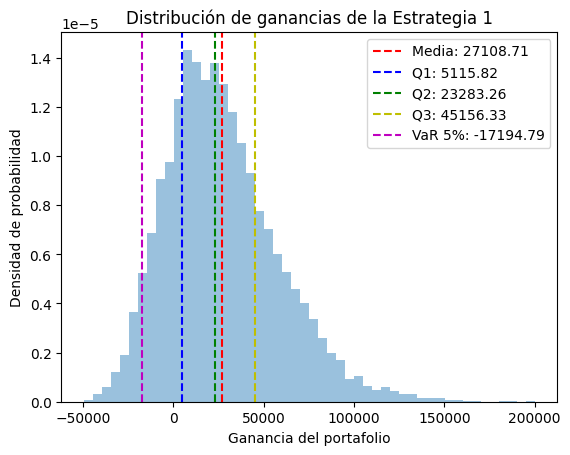

In [7]:
plt.hist(PyG_1, bins=50, density=True, histtype='stepfilled', alpha=0.45)
plt.xlabel('Ganancia del portafolio')
plt.ylabel('Densidad de probabilidad')
plt.title('Distribución de ganancias de la Estrategia 1')
plt.axvline(label = 'Media: {:.2f}'.format(np.mean(PyG_1)), x = np.mean(PyG_1), color = 'r', linestyle = '--')
plt.axvline(label = 'Q1: {:.2f}'.format(np.percentile(PyG_1, 25)), x = np.percentile(PyG_1, 25), color = 'b', linestyle = '--')
plt.axvline(label = 'Q2: {:.2f}'.format(np.percentile(PyG_1, 50)), x = np.percentile(PyG_1, 50), color = 'g', linestyle = '--')
plt.axvline(label = 'Q3: {:.2f}'.format(np.percentile(PyG_1, 75)), x = np.percentile(PyG_1, 75), color = 'y', linestyle = '--')
plt.axvline(label = 'VaR 5%: {:.2f}'.format(np.percentile(PyG_1, 5)), x = np.percentile(PyG_1, 5), color = 'm', linestyle = '--')
plt.legend()
plt.show()

La ganancia de la Estrategia 1 tiene una media de 27,109 dólares, por encima de su mediana, de 23,283, y la mitad central de los escenarios queda entre 5,116 y 45,156, con una cola derecha más larga que la izquierda, ya que el precio final del movimiento browniano geométrico no puede caer por debajo de cero pero sí multiplicarse, mientras que el VaR al 5%, la línea magenta, marca una pérdida de 17,195, de modo que uno de cada veinte escenarios pierde al menos esa cantidad.

## 5. Estrategia 2, equiponderada

La segunda estrategia reparte el capital en partes casi iguales, $\omega = [0.33, 0.33, 0.34]$, con lo cual sólo una tercera parte queda en AAPL y las otras dos en MSFT y NVDA, las acciones de menor rendimiento del año.

In [8]:
capital = 100000

w_2 = np.array([0.33, 0.33, 0.34])
values = capital*w_2
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_2 = valor_port - capital

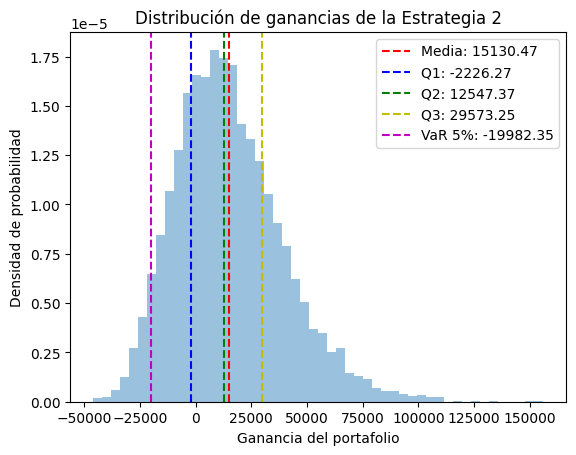

In [9]:
plt.hist(PyG_2, bins=50, density=True, histtype='stepfilled', alpha=0.45)
plt.xlabel('Ganancia del portafolio')
plt.ylabel('Densidad de probabilidad')
plt.title('Distribución de ganancias de la Estrategia 2')
plt.axvline(label = 'Media: {:.2f}'.format(np.mean(PyG_2)), x = np.mean(PyG_2), color = 'r', linestyle = '--')
plt.axvline(label = 'Q1: {:.2f}'.format(np.percentile(PyG_2, 25)), x = np.percentile(PyG_2, 25), color = 'b', linestyle = '--')
plt.axvline(label = 'Q2: {:.2f}'.format(np.percentile(PyG_2, 50)), x = np.percentile(PyG_2, 50), color = 'g', linestyle = '--')
plt.axvline(label = 'Q3: {:.2f}'.format(np.percentile(PyG_2, 75)), x = np.percentile(PyG_2, 75), color = 'y', linestyle = '--')
plt.axvline(label = 'VaR 5%: {:.2f}'.format(np.percentile(PyG_2, 5)), x = np.percentile(PyG_2, 5), color = 'm', linestyle = '--')
plt.legend()
plt.show()

La distribución de la Estrategia 2 es más estrecha que la de la Estrategia 1, con una mitad central que va de una pérdida de 2,226 a una ganancia de 29,573, a pesar de que dos terceras partes del capital están ahora en acciones más volátiles que AAPL, lo cual es efecto de la baja correlación de la sección 2.

La distribución también se desplaza a la izquierda, ya que la media baja a 15,130 dólares y la mediana a 12,547, de modo que el VaR al 5% empeora a una pérdida de 19,982, porque la menor dispersión no alcanza a compensar el menor rendimiento de MSFT y NVDA.

## 6. Estrategia 3, 60% en NVDA

La tercera estrategia carga 60% del capital en NVDA y reparte el resto en partes iguales entre AAPL y MSFT, $\omega = [0.2, 0.2, 0.6]$, con lo cual concentra el portafolio en la acción más volátil de la muestra.

In [10]:
capital = 100000

w_3 = np.array([0.2, 0.2, 0.6])
values = capital*w_3
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_3 = valor_port - capital

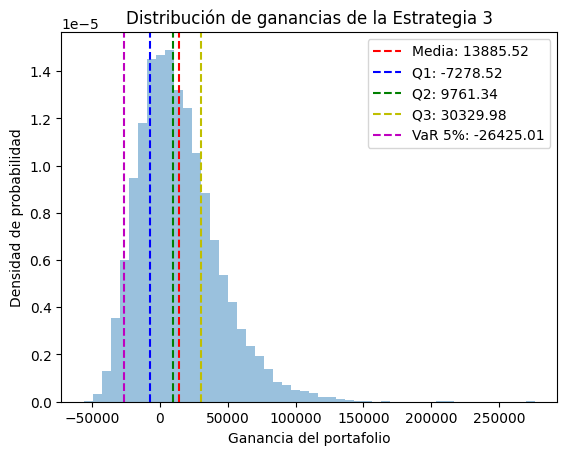

In [11]:
plt.hist(PyG_3, bins=50, density=True, histtype='stepfilled', alpha=0.45)
plt.xlabel('Ganancia del portafolio')
plt.ylabel('Densidad de probabilidad')
plt.title('Distribución de ganancias de la Estrategia 3')
plt.axvline(label = 'Media: {:.2f}'.format(np.mean(PyG_3)), x = np.mean(PyG_3), color = 'r', linestyle = '--')
plt.axvline(label = 'Q1: {:.2f}'.format(np.percentile(PyG_3, 25)), x = np.percentile(PyG_3, 25), color = 'b', linestyle = '--')
plt.axvline(label = 'Q2: {:.2f}'.format(np.percentile(PyG_3, 50)), x = np.percentile(PyG_3, 50), color = 'g', linestyle = '--')
plt.axvline(label = 'Q3: {:.2f}'.format(np.percentile(PyG_3, 75)), x = np.percentile(PyG_3, 75), color = 'y', linestyle = '--')
plt.axvline(label = 'VaR 5%: {:.2f}'.format(np.percentile(PyG_3, 5)), x = np.percentile(PyG_3, 5), color = 'm', linestyle = '--')
plt.legend()
plt.show()

La Estrategia 3 tiene la media más baja de las tres, de 13,886 dólares, y una mediana de 9,761, con una mitad central que va de una pérdida de 7,279 a una ganancia de 30,330, ya que el peso de NVDA, la acción más volátil y de rendimiento bajo en el año, ensancha la distribución hacia ambos lados sin mover su centro hacia arriba, y con ello su VaR al 5% llega a una pérdida de 26,425, la mayor de las tres.

## 7. VaR y CVaR de las tres estrategias

El VaR al 5% es el percentil 5 de la ganancia simulada, la pérdida que sólo se rebasa en 5% de los escenarios, de modo que con 95% de confianza la estrategia no pierde más que esa cifra en un año, mientras que el CVaR al 5% es el promedio de la ganancia en los escenarios que quedan por debajo del VaR y responde a lo que el VaR deja abierto, cuánto se pierde en promedio cuando ese umbral se rebasa.

$$\text{VaR}_{5\%} = q_{0.05}(G), \qquad \text{CVaR}_{5\%} = \mathbb{E}\left[\,G \mid G \le \text{VaR}_{5\%}\,\right]$$

In [12]:
def Riesgo(PyG):
    VaR_5 = np.percentile(PyG, 5)
    CVaR_5 = np.mean(PyG[PyG <= VaR_5])
    
    return VaR_5, CVaR_5

In [13]:
Riesgo_Portafolios = pd.DataFrame({
    'Estrategia 1': Riesgo(PyG_1),
    'Estrategia 2': Riesgo(PyG_2),
    'Estrategia 3': Riesgo(PyG_3)
}, index=['VaR 5%', 'CVaR 5%'])

Riesgo_Portafolios

,Estrategia 1,Estrategia 2,Estrategia 3
VaR 5%,-17194.789493,-19982.345013,-26425.014740
CVaR 5%,-24857.806402,-26010.134610,-32746.075742


Las tres estrategias tienen un VaR negativo, es decir, una pérdida, de 17,195 dólares en la Estrategia 1, 19,982 en la 2 y 26,425 en la 3, y su CVaR la amplía a 24,858, 26,010 y 32,746, de modo que en el peor 5% de los escenarios la pérdida promedio supera al VaR en 7,663, 6,028 y 6,321 dólares, diferencia que mide el peso de la cola más allá del umbral y que sigue el orden de la desviación estándar de cada estrategia.

In [14]:
Ganancias = pd.DataFrame({'Estrategia 1': PyG_1, 'Estrategia 2': PyG_2, 'Estrategia 3': PyG_3})
Resumen = Ganancias.describe(percentiles=[0.05, 0.25, 0.5, 0.75]).T
Resumen['% de escenarios con pérdida'] = (Ganancias < 0).mean() * 100
Resumen.round(2)

,count,mean,std,min,5%,25%,50%,75%,max,% de escenarios con pérdida
Estrategia 1,10000.0,27108.71,31266.41,-49439.75,-17194.79,5115.82,23283.26,45156.33,200005.78,18.88
Estrategia 2,10000.0,15130.47,24331.46,-46336.66,-19982.35,-2226.27,12547.37,29573.25,156237.56,28.55
Estrategia 3,10000.0,13885.52,29609.98,-56148.03,-26425.01,-7278.52,9761.34,30329.98,276279.23,35.51


El orden del riesgo no coincide con el de la dispersión, ya que la Estrategia 1 tiene la desviación más alta, de 31,266 dólares, y aun así el VaR menos severo, porque su media de 27,109 aleja toda la distribución del cero, mientras que la Estrategia 2, la menos dispersa, con 24,331, pierde esa ventaja por una media de 15,130, y la Estrategia 3 junta una media baja, de 13,886, con una desviación alta, de 29,610, por lo cual tiene el peor VaR, el peor CVaR, la peor pérdida simulada, de 56,148, y la mayor proporción de escenarios con pérdida, 35.51%, frente a 28.55% de la Estrategia 2 y 18.88% de la 1.

## 8. Conclusiones

Con 100,000 dólares a un año, la estrategia concentrada en AAPL resultó la de menor riesgo según el VaR y el CVaR al 5%, con pérdidas de 17,195 y 24,858 dólares, frente a 19,982 y 26,010 de la equiponderada y 26,425 y 32,746 de la cargada a NVDA, aun cuando es la más dispersa de las tres, con una desviación de 31,266 dólares.

La explicación está en que el VaR y el CVaR miden la cola izquierda de la ganancia y no su dispersión alrededor de la media, de modo que dependen tanto del centro de la distribución como de su ancho, y en el último año AAPL tuvo una media logarítmica de 0.2116 contra 0.0212 de MSFT y 0.0422 de NVDA, ventaja que desplaza toda su distribución a la derecha y compensa la falta de diversificación, mientras que la baja correlación entre las tres acciones sí redujo la dispersión de la Estrategia 2, aunque no lo suficiente para compensar que dos terceras partes del capital quedaran en acciones que casi no subieron.

La consecuencia es que la desviación estándar, la medida de riesgo de C16-C17, y el VaR pueden ordenar las mismas estrategias de forma distinta, por lo cual conviene reportarlas juntas y acompañarlas del CVaR, que además indica cuánto se pierde más allá del umbral, de 6,028 a 7,663 dólares adicionales en promedio, y entre las tres estrategias la recomendación es la primera, siempre que se acepte que su ventaja depende por completo de que AAPL repita su año.

El análisis tiene dos límites, ya que los parámetros se estimaron con sólo 250 rendimientos diarios, de modo que la media, el parámetro que más pesa en el VaR de este ejercicio, es también el que peor se estima con una muestra tan corta, y además el VaR y el CVaR heredan los supuestos del modelo, rendimientos normales con una correlación constante, que subestiman la frecuencia de las caídas fuertes, por lo cual la extensión natural es repetir el cálculo con distintas ventanas de estimación y contrastar el VaR simulado con el VaR histórico de la propia muestra.